In [1]:
import matplotlib.pyplot as plt
import torch
from torch import nn


In [2]:
# ============================================================
# 1. Reproducibility
# ============================================================

torch.manual_seed(42)


In [3]:
# ============================================================
# 2. Generate training and validation data
# ============================================================

N = 5000

# Randomly sample x from [-100, 100]
x = -100 + 200 * torch.rand(N, 1)

# Target: sin(x)
y = torch.sin(x)

# Shuffle and split 80/20
indices = torch.randperm(N)

train_size = int(0.8 * N)

train_idx = indices[:train_size]
val_idx = indices[train_size:]

x_train = x[train_idx]
y_train = y[train_idx]

x_val = x[val_idx]
y_val = y[val_idx]


In [4]:
# ============================================================
# 3. Normalize the input
# ============================================================
#
# x is originally in [-100, 100].
# We transform it approximately to [-1, 1].
#
# This generally makes neural-network optimization easier.
# ============================================================

x_train_norm = x_train / 100
x_val_norm = x_val / 100


In [5]:
# ============================================================
# 4. Define the neural network
# ============================================================

class SineNet(nn.Module):

    def __init__(self, hidden_layer_width=128):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1, hidden_layer_width),
            nn.Tanh(),

            nn.Linear(hidden_layer_width, hidden_layer_width),
            nn.Tanh(),

            nn.Linear(hidden_layer_width, 1)
        )

    def forward(self, x):
        return self.network(x)


model = SineNet()

print(model)



SineNet(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Tanh()
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [6]:
# ============================================================
# 5. Loss function and optimizer
# ============================================================

loss_fn = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


In [7]:
# ============================================================
# 6. Training loop
# ============================================================

epochs = 20_000

train_losses = []
val_losses = []

for epoch in range(epochs):

    # ----------------------------------------
    # Training mode
    # ----------------------------------------

    model.train()

    # Forward pass
    predictions = model(x_train_norm)

    # Calculate loss
    loss = loss_fn(predictions, y_train)

    # Clear old gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update model parameters
    optimizer.step()


    # ----------------------------------------
    # Validation
    # ----------------------------------------

    model.eval()

    with torch.no_grad():

        val_predictions = model(x_val_norm)

        val_loss = loss_fn(
            val_predictions,
            y_val
        )

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())


    # ----------------------------------------
    # Print progress
    # ----------------------------------------

    if (epoch + 1) % 500 == 0:

        print(
            f"Epoch {epoch + 1:5d} | "
            f"Train Loss: {loss.item():.6f} | "
            f"Val Loss: {val_loss.item():.6f}"
        )


Epoch   500 | Train Loss: 0.495528 | Val Loss: 0.535057
Epoch  1000 | Train Loss: 0.495251 | Val Loss: 0.535057
Epoch  1500 | Train Loss: 0.494993 | Val Loss: 0.534972
Epoch  2000 | Train Loss: 0.494519 | Val Loss: 0.534403
Epoch  2500 | Train Loss: 0.494347 | Val Loss: 0.533941
Epoch  3000 | Train Loss: 0.493741 | Val Loss: 0.533110
Epoch  3500 | Train Loss: 0.493479 | Val Loss: 0.533122
Epoch  4000 | Train Loss: 0.492677 | Val Loss: 0.532899
Epoch  4500 | Train Loss: 0.486079 | Val Loss: 0.526959
Epoch  5000 | Train Loss: 0.475659 | Val Loss: 0.516739
Epoch  5500 | Train Loss: 0.459172 | Val Loss: 0.500782
Epoch  6000 | Train Loss: 0.438746 | Val Loss: 0.481764
Epoch  6500 | Train Loss: 0.412951 | Val Loss: 0.456463
Epoch  7000 | Train Loss: 0.386159 | Val Loss: 0.429103
Epoch  7500 | Train Loss: 0.368011 | Val Loss: 0.409494
Epoch  8000 | Train Loss: 0.347491 | Val Loss: 0.382631
Epoch  8500 | Train Loss: 0.310174 | Val Loss: 0.337011
Epoch  9000 | Train Loss: 0.273000 | Val Loss: 0

In [8]:
# ============================================================
# 7. Create interpolation test data
# ============================================================

x_test_inside = torch.linspace(
    -100,
    100,
    1000
).reshape(-1, 1)

y_test_inside = torch.sin(x_test_inside)

x_test_inside_norm = x_test_inside / 100


In [9]:
# ============================================================
# 8. Create extrapolation test data
# ============================================================

x_test_outside = torch.linspace(
    -1000,
    1000,
    1000
).reshape(-1, 1)

y_test_outside = torch.sin(x_test_outside)

x_test_outside_norm = x_test_outside / 100


In [10]:
# ============================================================
# 9. Evaluate the model
# ============================================================

model.eval()

with torch.no_grad():

    pred_inside = model(x_test_inside_norm)

    pred_outside = model(x_test_outside_norm)

    inside_loss = loss_fn(
        pred_inside,
        y_test_inside
    )

    outside_loss = loss_fn(
        pred_outside,
        y_test_outside
    )


print()
print("Evaluation")
print("-----------------------------")
print(f"Interpolation MSE: {inside_loss.item():.6f}")
print(f"Extrapolation MSE: {outside_loss.item():.6f}")



Evaluation
-----------------------------
Interpolation MSE: 0.001071
Extrapolation MSE: 1.035617


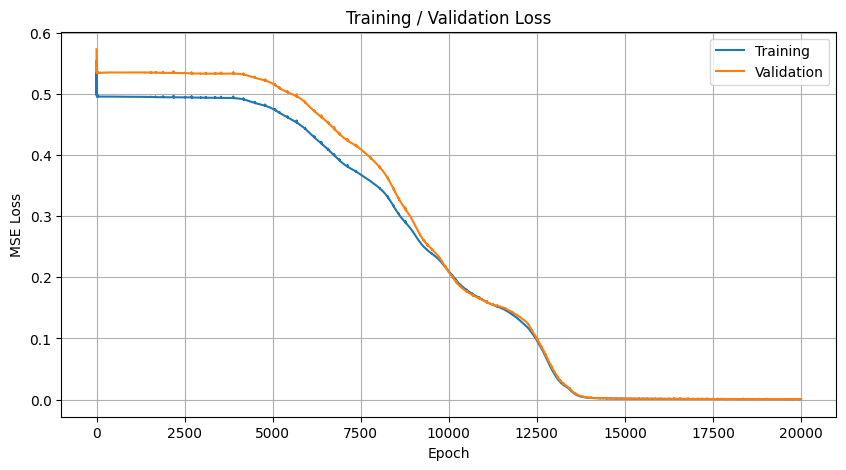

In [11]:
# ============================================================
# 10. Plot training loss
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training")
plt.plot(val_losses, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training / Validation Loss")

plt.legend()
plt.grid(True)

plt.show()


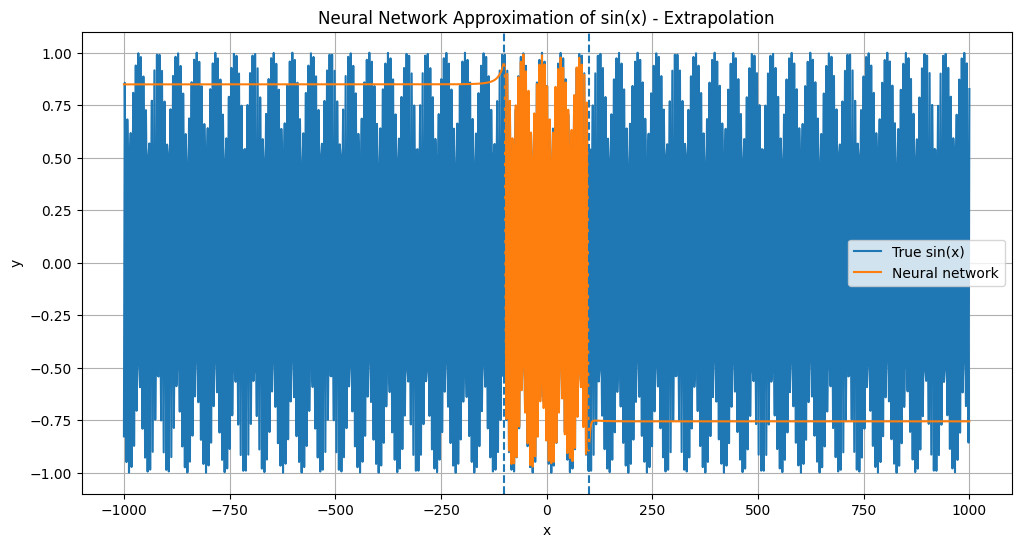

In [12]:
# ============================================================
# 11. Plot learned sine function (extrapolation)
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    x_test_outside.numpy(),
    y_test_outside.numpy(),
    label="True sin(x)"
)

plt.plot(
    x_test_outside.numpy(),
    pred_outside.numpy(),
    label="Neural network"
)

plt.axvline(-100, linestyle="--")
plt.axvline(100, linestyle="--")

plt.xlabel("x")
plt.ylabel("y")

plt.title("Neural Network Approximation of sin(x) - Extrapolation")

plt.legend()
plt.grid(True)

plt.show()


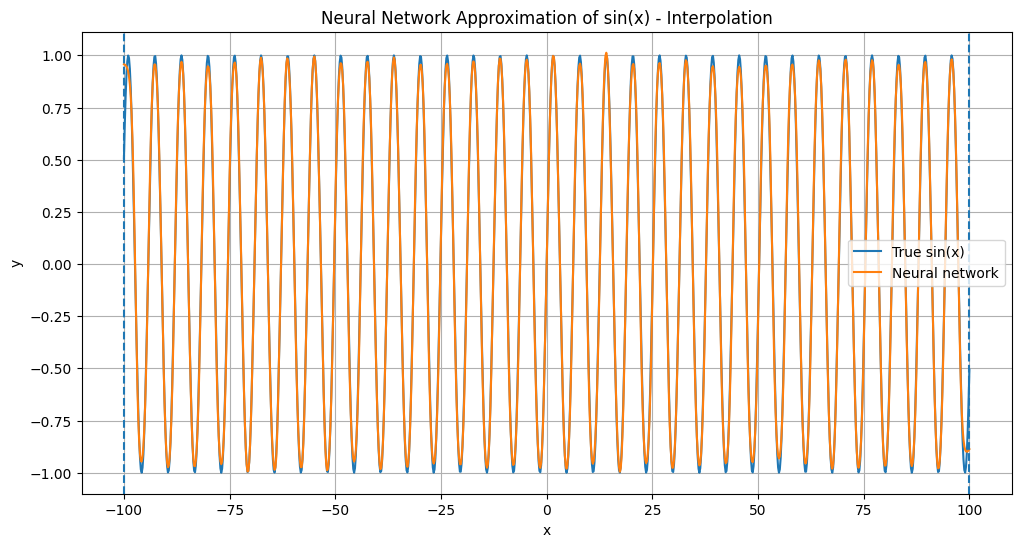

In [13]:
# ============================================================
# 12. Plot learned sine function (same distribution/inetrpolation)
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    x_test_inside.numpy(),
    y_test_inside.numpy(),
    label="True sin(x)"
)

plt.plot(
    x_test_inside.numpy(),
    pred_inside.numpy(),
    label="Neural network"
)

plt.axvline(-100, linestyle="--")
plt.axvline(100, linestyle="--")

plt.xlabel("x")
plt.ylabel("y")

plt.title("Neural Network Approximation of sin(x) - Interpolation")

plt.legend()
plt.grid(True)

plt.show()
